In [66]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Checkpoint continuations and numerical branch consistency

Does deterioration persist when a self-training configuration is frozen, or does changing selection and pseudo-labels contribute additional deterioration? Can correcting targets on the same selected observations improve the outcome? Is the unconstrained minimizer of a fitted configuration consistent with the configuration that generated it?

This notebook studies these distinct questions using common-checkpoint continuations. It loads the additive experiment layer's cache and never implements training. The three-seed pilot retains Notebook 14's existing fixed-pool collapse settings; the paired construction changes the realized dataset and therefore need not reproduce the original seed's outcome. Contradictory runs are retained. Checkpoints use exact population error retrospectively and are **not deployable stopping rules**.

Sources: the supplied *Mean Field Dynamics of Self Training via Gradient Descent*, section 7 (fixed-pool objective and preconditioned dynamics, equation 117); the repository's [finite engine](../src/algorithms.py), [initialization](../src/initialization.py), [residual primitives](../src/primitives.py), and [Notebook 14](14_unlabeled_loss_normalization.ipynb).

## Model, scaling, and initialization

The model and score are
$$
X_i=Y_i\mu/\sqrt d+\sigma U_i,\qquad r_i=b+X_i^\top w/\sqrt d,
\quad \ell(y,r)=\log(1+e^{-yr}),\quad J(w)=\|w\|^2/(2d).
$$
There is no intercept penalty. For a fixed target vector $q_j\in\{-1,+1\}$ and selection $a_j\in\{0,1\}$, the engine uses
$$
\begin{aligned}
b^+&=b+\frac\eta N\sum_{i\in L}Y_i\operatorname{sigmoid}(-Y_i r_i)
       +\frac{\eta\pi}M\sum_{j\in U}a_jq_j\operatorname{sigmoid}(-q_jr_j),\\
w^+&=(1-\eta\lambda)w+\frac{\eta\sqrt d}N\sum_{i\in L}X_iY_i\operatorname{sigmoid}(-Y_i r_i)
       +\frac{\eta\pi\sqrt d}M\sum_{j\in U}X_ja_jq_j\operatorname{sigmoid}(-q_jr_j).
\end{aligned}
$$
This is gradient descent preconditioned by $\operatorname{diag}(1,dI_d)$ in $(b,w)$, equivalently ordinary gradient descent in $(b,v=w/\sqrt d)$. Every unlabeled denominator remains **the fixed original pool size $M$**, including empty selections. The suite explicitly passes `normalize_unlabeled_loss=False`; the legacy default `True` divides by the current selected count through $S/\omega$, and remains unchanged.

The pilot uses $b^0=0$, independent standard Gaussian $w^0$, Gaussian signal coordinates, and exogenous independent Rademacher unlabeled $Y^{\rm init}$, with labeled entries equal to their labels. At the special first update $t=0$, the engine uses $Y^{\rm init}$, not score signs. From $t=1$, selected targets are score signs. At each checkpoint $t_0\ge1$, replay starts with the checkpoint's signs so its first local update reproduces the correct global step. Stable sigmoid and `logaddexp` evaluations are used in training/optimization.

In [67]:
from pathlib import Path
import os
import sys
import numpy as np
import pandas as pd
# Embed figures in the notebook even under a headless runner.
get_ipython().run_line_magic("matplotlib", "inline")
from matplotlib import pyplot as plt
from IPython.display import Markdown, display

HERE = Path.cwd().resolve()
ROOT = next((path for path in (HERE, *HERE.parents)
             if (path / "src").is_dir() and (path / "experiments" / "confirmation_bias").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Run this notebook from the repository or its notebooks directory.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import importlib
from experiments.confirmation_bias import config as config_module
from experiments.confirmation_bias import runner as runner_module
# Refresh edited presets and notebook orchestration in an existing kernel.
importlib.reload(config_module)
importlib.reload(runner_module)
preset = config_module.preset
from experiments.confirmation_bias import reporting as report

pd.set_option("display.max_columns", 18)
pd.set_option("display.max_colwidth", 85)

In [68]:
PROFILE = os.environ.get("CONFIRMATION_PROFILE", "smoke")  # smoke | pilot | expanded
ALLOW_RUN = False  # opt-in only; opening/executing never starts a missing sweep by default
# Refresh configuration source when this cell is rerun after editing config.py.
importlib.reload(config_module)
CONFIG = config_module.preset(PROFILE)
OUTPUT_ROOT = ROOT / "outputs" / "confirmation_bias"
print(f"Profile={PROFILE}; seeds={CONFIG.seeds}; d={CONFIG.d}; N={CONFIG.n_labeled}; "
      f"M={CONFIG.n_unlabeled}; T={CONFIG.T}; priors={CONFIG.imbalance_levels}")

Profile=smoke; seeds=(49,); d=2000; N=320; M=15680; T=300; priors=(0.5, 0.35, 0.2)


## Load the matching cache and record provenance

Results are separated by a configuration identifier. Saved metadata includes the configuration, seeds, solver settings, software/repository information, and completion status. The default profile is a small execution check. To study the substantive setting, first run `PYTHONPATH=. python3 -m experiments.confirmation_bias.runner --profile pilot`, then execute this notebook with `CONFIRMATION_PROFILE=pilot`. No sweep is launched merely by opening or executing the default notebook.

In [69]:
# Pass the exact CONFIG, including notebook overrides, to both run and load.
# Complete caches are reused even when ALLOW_RUN=True.
suite = runner_module.load_or_run_suite(
    CONFIG, output_root=OUTPUT_ROOT, allow_run=ALLOW_RUN, threads=2,
)

tables = report.export_tables(suite)
print("Cache:", suite["output_dir"])
display(pd.DataFrame([suite["config"]]))
display(suite["metadata"])
if PROFILE == "smoke":
    display(Markdown("**Validation profile:** reduced dimensions and horizon. Smoke outputs are not evidence for the scientific collapse hypothesis."))

Cache: /Users/thierryrioual/Desktop/Princeton/Academics/Research/implementation/outputs/confirmation_bias/smoke-06ed2f749f3dd76a


,d,n_labeled,n_unlabeled,T,p_c,sigma,signal_std,eta,penalty,...,profile,solver_gtol,solver_ftol,solver_maxiter,solver_maxls,solver_residual_tolerance,consistency_tolerance,deterioration_tolerance,replay_tolerance
0,2000,320,15680,300,0.2,1.0,1.0,0.5,0.1,...,smoke,1.000000e-08,1.000000e-15,1500,40,0.000001,1.000000e-07,1.000000e-08,1.000000e-10


{'configuration_id': 'smoke-06ed2f749f3dd76a',
 'schema_version': 1,
 'config': {'d': 2000,
  'n_labeled': 320,
  'n_unlabeled': 15680,
  'T': 300,
  'p_c': 0.2,
  'sigma': 1.0,
  'signal_std': 1.0,
  'eta': 0.5,
  'penalty': 0.1,
  'pi': 2.0,
  'kappa_minus': -1.3862943611198906,
  'kappa_plus': 1.3862943611198906,
  'seeds': [49],
  'profile': 'smoke',
  'solver_gtol': 1e-08,
  'solver_ftol': 1e-15,
  'solver_maxiter': 1500,
  'solver_maxls': 40,
  'solver_residual_tolerance': 1e-06,
  'consistency_tolerance': 1e-07,
  'deterioration_tolerance': 1e-08,
  'replay_tolerance': 1e-10},
 'software': {'python': '3.9.6 (default, Apr 30 2025, 02:07:17) \n[Clang 17.0.0 (clang-1700.0.13.5)]',
  'platform': 'macOS-26.6.2-arm64-arm-64bit',
  'numpy': '2.0.2',
  'scipy': '1.13.1',
  'torch': '2.8.0',
  'git_commit': 'c0b35e69887b814535424ebaeafc43adbf84427b',
  'git_status': 'M .DS_Store\n M .gitignore\n M notebooks/14_unlabeled_loss_normalization.ipynb\n?? .Rhistory\n?? experiments/\n?? notebook

**Validation profile:** reduced dimensions and horizon. Smoke outputs are not evidence for the scientific collapse hypothesis.

## Population error and retrospective checkpoints

For $\tau=\|w\|/\sqrt d>0$, $m=\mu^\top w/d$, and population prior $p=\Pr(Y=+1)$, the exact conditional classification error is
$$
\mathcal E=p\Phi\!\left(\frac{-b-m}{\sigma\tau}\right)
+(1-p)\Phi\!\left(\frac{b-m}{\sigma\tau}\right).
$$
It is an analytic population quantity conditional on the fitted parameter, not a test-set estimate. At $\tau=0$, use the actual constant prediction: `sign(0)=+1`; $b\ge0$ has error $1-p$, and $b<0$ has error $p$. The normalized quantities $b/\tau,m/\tau$ are undefined (`NaN`) there.

Let $t_{\rm best}$ be the **earliest** minimizer over states $1,\ldots,T$. Use the distinct checkpoints $\max\{1,\lfloor t_{\rm best}/2\rfloor\}$ and $t_{\rm best}$. Deterioration is $\mathcal E_T-\mathcal E_{t_{\rm best}}$, with the configured numerical tolerance. The following table keeps every seed, including cases without deterioration.

In [70]:
runs = report.select_runs(suite, CONFIG.p_c)
collapse_rows = tables["baselines"][np.isclose(tables["baselines"]["p"], CONFIG.p_c)]
display(collapse_rows[["seed", "p", "t_best", "best_error", "terminal_error", "deterioration", "deteriorated",
                       "terminal_configuration_type", "first_fully_negative_selected_iteration", "last_observed_switch"]])

,seed,p,t_best,best_error,terminal_error,deterioration,deteriorated,terminal_configuration_type,first_fully_negative_selected_iteration,last_observed_switch
2,49,0.2,43,0.1651,0.199986,0.034886,True,negative selected plus zeros,None,293


## Three continuations from the identical state

At a checkpoint, define $p^0_j=-1$ if $r_j\le\kappa_-$, $p^0_j=0$ if $\kappa_-<r_j<\kappa_+$, and $p^0_j=+1$ if $r_j\ge\kappa_+$. Set $A_0=\{j:p^0_j\ne0\}$. Equality is selected at either threshold; prediction signs and selection are distinct.

- **Dynamic:** recompute both selection and pseudo-labels at every step.
- **Frozen:** retain exactly $A_0$ and its assigned targets $p^0$, even when scores later cross thresholds or change sign.
- **Frozen selected oracle:** retain exactly $A_0$ and replace its assigned targets by true labels. No other unlabeled observation enters the objective.

All three use identical data, checkpoint parameters, step size, $\pi$, ridge, denominator $M$, and remaining horizon. True unlabeled labels enter only diagnostics and the explicit oracle. Replay is checked against the original baseline suffix. Every row below is a within-trajectory comparison. Absolute and relative iteration views are shown side by side; different seeds' checkpoints need not coincide.

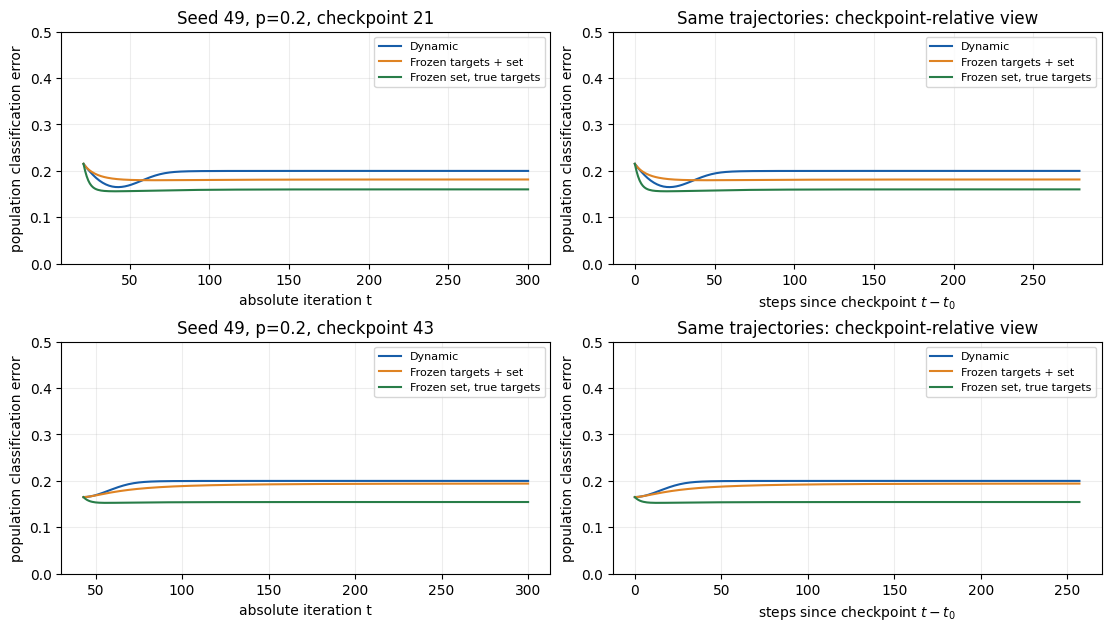

,seed,p,t0,branch,checkpoint_error,terminal_error,error_change_from_checkpoint,terminal_b,terminal_normalized_bias,terminal_normalized_alignment,observed_switches,replay_max_abs,first_fully_negative_selected_iteration,last_observed_switch,total_configuration_switches,terminal_configuration_type
12,49,0.2,21,dynamic,0.215182,0.199986,-0.015195,-4.839954,-3.957630,0.274015,9156,0.0,None,293.0,9156,negative selected plus zeros
13,49,0.2,21,frozen,0.215182,0.181493,-0.033688,-1.810408,-1.259811,0.540791,4329,0.0,None,290.0,4329,both selected signs plus zeros
14,49,0.2,21,oracle,0.215182,0.160180,-0.055002,-1.552046,-1.110013,0.698213,5770,0.0,None,267.0,5770,both selected signs plus zeros
15,49,0.2,43,dynamic,0.165100,0.199986,0.034886,-4.839954,-3.957630,0.274015,5027,0.0,None,293.0,5027,negative selected plus zeros
16,49,0.2,43,frozen,0.165100,0.194225,0.029125,-3.136442,-2.390724,0.577161,3971,0.0,None,297.0,3971,both selected signs plus zeros
17,49,0.2,43,oracle,0.165100,0.154500,-0.010600,-1.571491,-1.076955,0.736890,3012,0.0,None,206.0,3012,both selected signs plus zeros


In [71]:
fig = report.plot_checkpoint_errors(runs)
report.save_figure(suite, fig, "15_checkpoint_errors")
display(fig)
plt.close(fig)
continuations = tables["continuations"][np.isclose(tables["continuations"]["p"], CONFIG.p_c)]
display(continuations)

## Parameter motion, predictions, and configuration changes

The next panels display each continuation's intercept, normalized bias/alignment, **score-induced** configurations, positive predictions, and complete configuration switches. The fitted configuration for a frozen run is still $p^0$; it does not change when its score-induced configuration changes. False-negative and false-positive fractions below use the current score-induced selected signs, divided by $M$, and are diagnostics rather than the fixed objective's assigned targets. Conditional selected error rates are also retained in the cache: each sign-specific rate divides by the count selected with that predicted sign (not by the true class count); the overall rate divides by all selected observations. Actual fixed-assignment error fractions are saved separately.

Every switch is counted, including direct $-1\leftrightarrow+1$. A last observed switch records a finite-history event; a switch-free interval is an observed plateau, not a certificate of permanent identification. Undefined normalized quantities remain missing in the plots.

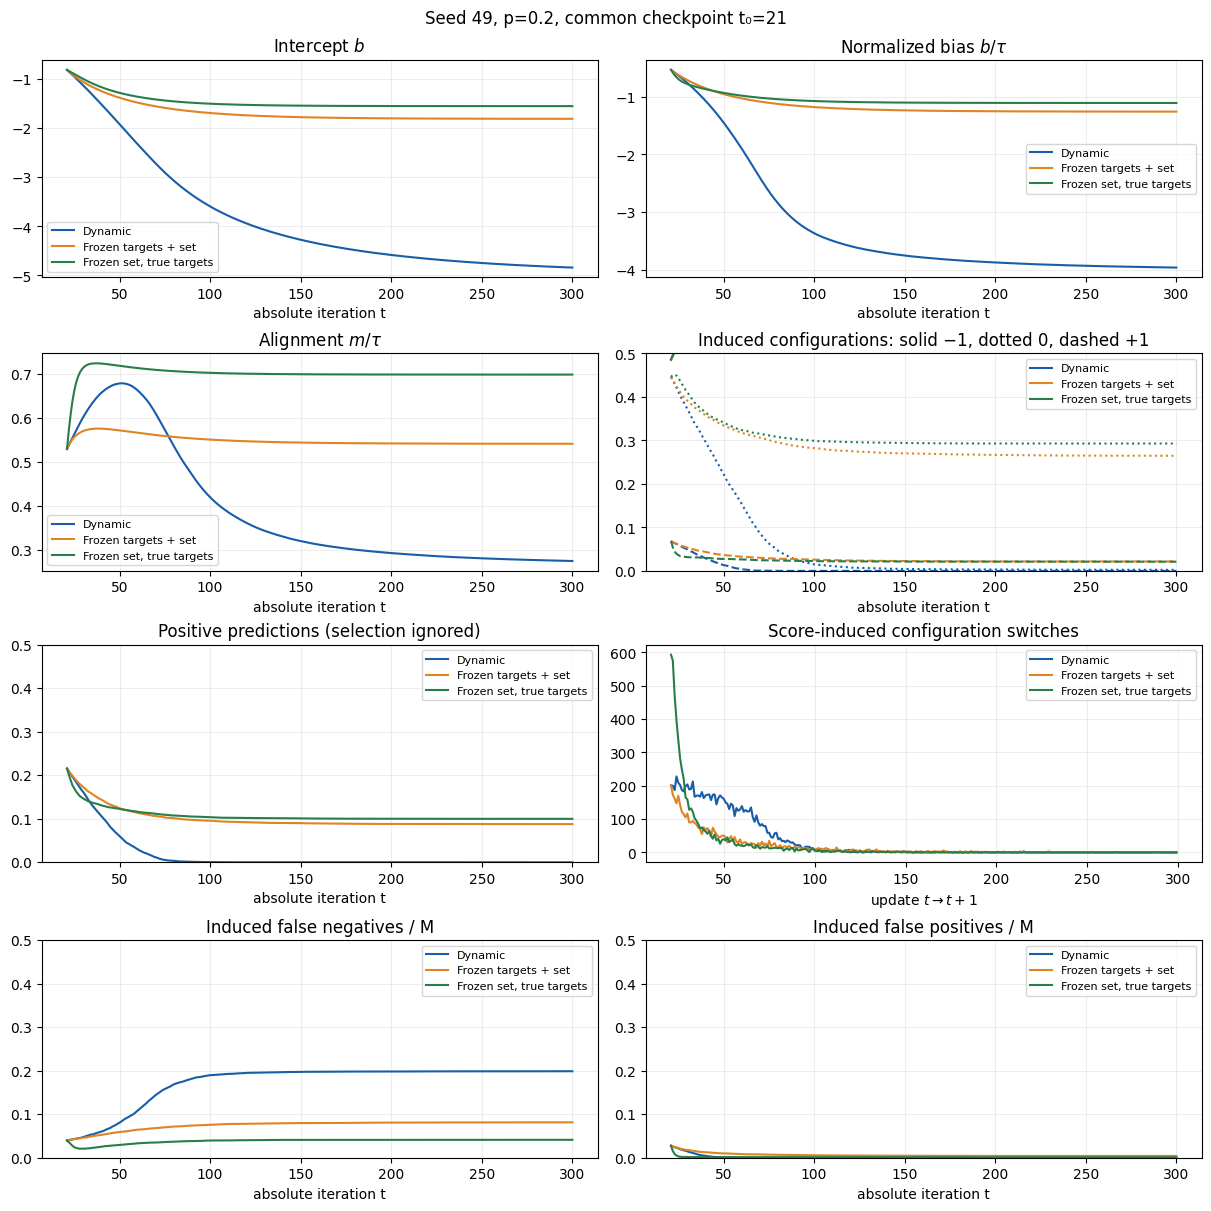

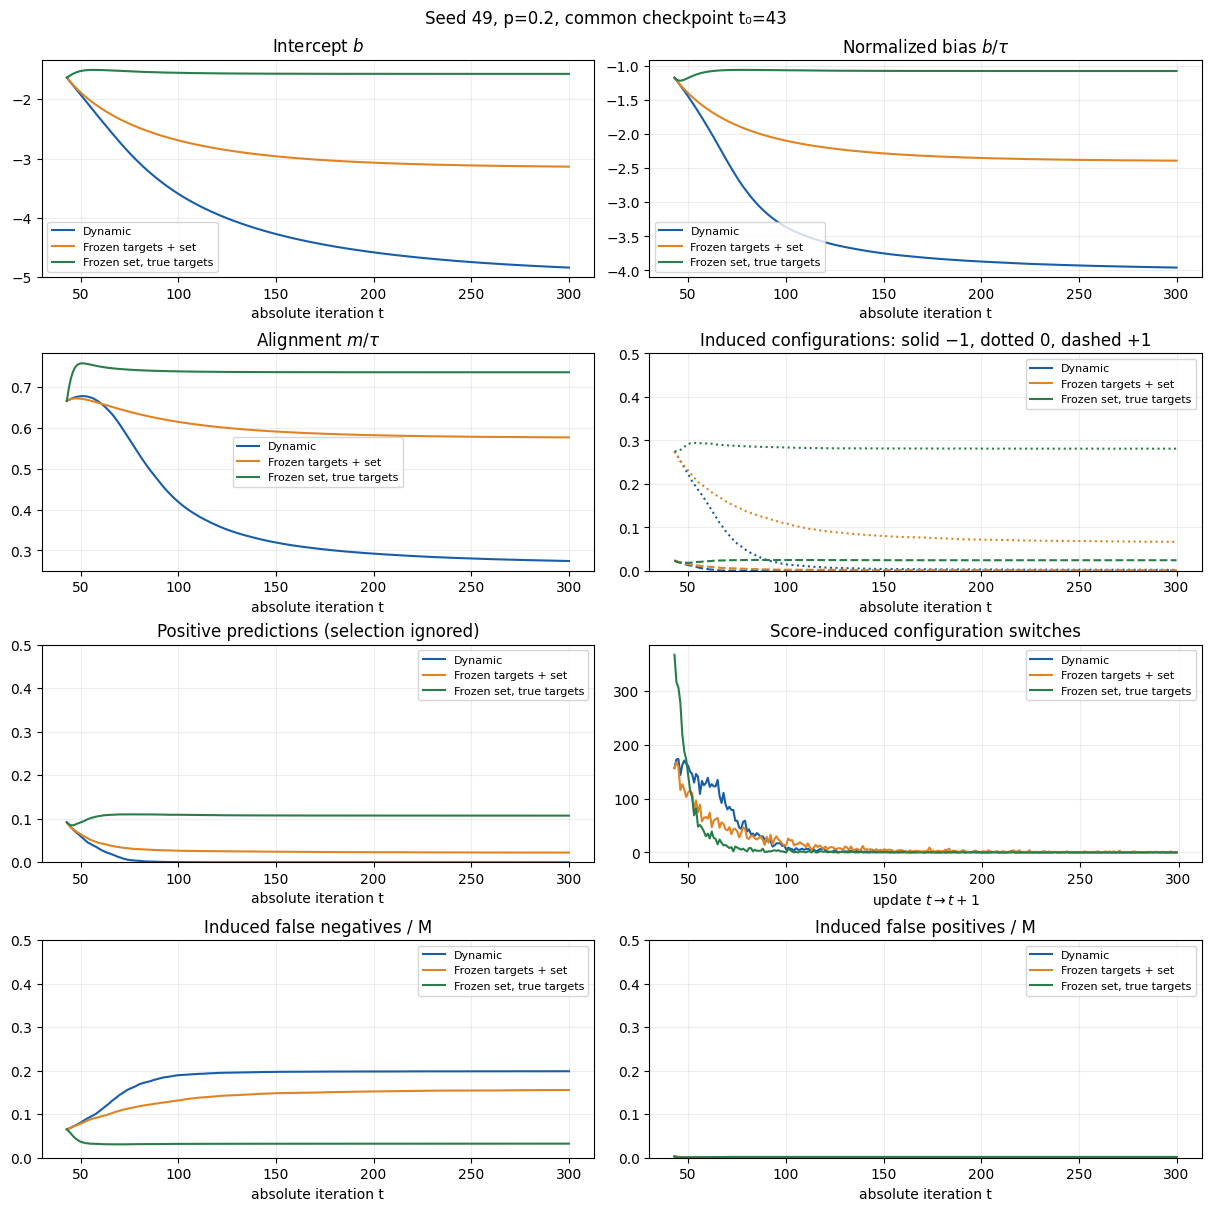

,seed,from_configuration,to_configuration,count
0,49,-1,-1,4231267
1,49,-1,0,590
2,49,-1,1,0
3,49,0,-1,14942
4,49,0,0,410114
5,49,0,1,1181
6,49,1,-1,3
7,49,1,0,2523
8,49,1,1,43380


In [72]:
for run in runs:
    for checkpoint in run["checkpoints"]:
        fig = report.plot_checkpoint_diagnostics(run, checkpoint)
        report.save_figure(suite, fig, f"15_diagnostics_seed{run['seed']}_t{checkpoint['t0']}")
        display(fig)
        plt.close(fig)

transitions = tables["baseline_transitions"]
transitions = transitions[np.isclose(transitions["p"], CONFIG.p_c)]
display(transitions.groupby(["seed", "from_configuration", "to_configuration"], as_index=False)["count"].sum())

## Intercept increments and threshold-crossing score increments

For ordinary dynamic self-training at $t\ge1$,
$$
\zeta_L=\frac\eta N\sum_{i\in L}Y_i\operatorname{sigmoid}(-Y_i r_i),\qquad
\zeta_U=\frac\eta M\sum_{j\in U}S_\kappa(r_j)\operatorname{sign}(r_j)
                     \operatorname{sigmoid}(-|r_j|),\qquad
\Delta b=\zeta_L+\pi\zeta_U.
$$
**$\zeta_U$ does not contain $\pi$.** At the exceptional initialization update, saved `zeta_U` uses the actual exogenous assigned targets, while `dynamic_self_label_zeta_U` is undefined. Frozen-run increments always use their fixed assignments, never the dynamic self-label formula.

With $\beta=M^{-1}\sum_j S_\kappa(r_j)Y_j\mathbf1\{\operatorname{sign}(r_j)\ne Y_j\}$, the pseudo-label increment minus the true-label increment on the **same selected observations at the same state** is $-\eta\pi\beta$. The saved identity residual uses actual assigned targets (`beta_assigned`), so it also covers initialization and frozen interventions; in dynamic updates $t\ge1$, `beta_assigned=beta`. This identity does not describe differences between diverging trajectories.

For each dynamic threshold crossing,
$$
\Delta r_j=\underbrace{\Delta b}_{\text{bias component}}
+\underbrace{X_j^\top\Delta w/\sqrt d}_{\text{feature component}}.
$$
Tables report crossing counts and count-weighted signed/absolute component means. A direct sign switch can cross both thresholds and is included in both event categories. These local algebraic summaries indicate which component accompanies recruitment; they are not an additive causal explanation of whole-trajectory changes.

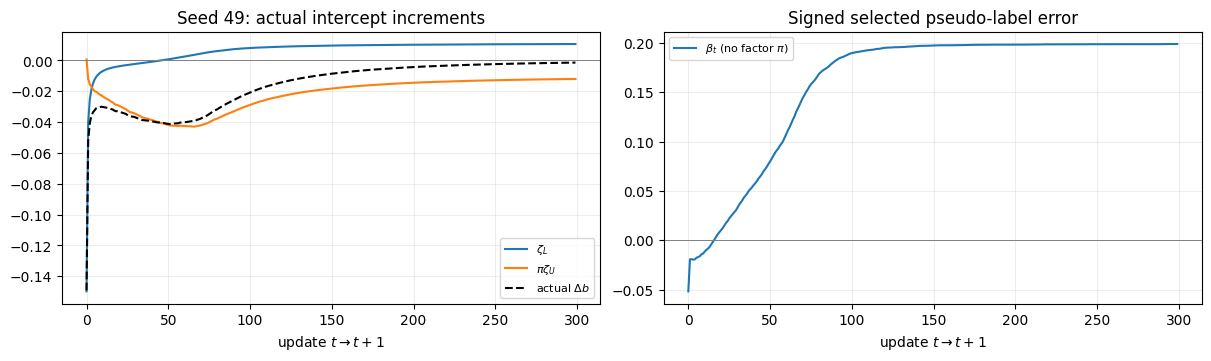

,seed,p,max_bias_decomposition_residual,max_one_step_oracle_identity_residual,oracle_identity_updates_checked
2,49,0.2,4.440892e-16,5.551115e-17,300


,seed,p,crossing,count,mean_bias,mean_feature,mean_total,mean_abs_bias,mean_abs_feature,mean_additivity_residual
8,49,0.2,minus_up,590,-0.131060,0.933355,0.802295,0.131060,0.933355,4.440892e-16
9,49,0.2,minus_down,14945,-0.048493,-0.158022,-0.206515,0.048493,0.160285,2.775558e-17
10,49,0.2,plus_up,1181,-0.084212,0.564516,0.480304,0.084212,0.564516,-1.110223e-16
11,49,0.2,plus_down,2526,-0.077082,-0.407473,-0.484556,0.077082,0.409426,-1.665335e-16


In [73]:
fig = report.plot_update_decomposition(runs, CONFIG.pi)
report.save_figure(suite, fig, "15_bias_update_decomposition")
display(fig)
plt.close(fig)
display(tables["one_step_identities"][np.isclose(tables["one_step_identities"]["p"], CONFIG.p_c)])
display(tables["threshold_crossings"][np.isclose(tables["threshold_crossings"]["p"], CONFIG.p_c)])

## Unconstrained convex minimization and numerical consistency

Independently of the finite continuations, minimize
$$
L_{p^0}(b,w)=\frac1N\sum_{i\in L}\ell(Y_i,r_i)
+\frac\pi M\sum_{j\in A_0}\ell(p^0_j,r_j)+\frac\lambda{2d}\|w\|^2,
$$
and its oracle version replacing $p^0_j$ by $Y_j$. These are **unconstrained** branch objectives: the optimizer never projects scores onto branch inequalities. L-BFGS-B uses analytic gradients in $(b,v=w/\sqrt d)$, where the penalty is $\lambda\|v\|^2/2$; $w=\sqrt d\,v$ is restored afterward. Positive ridge and both labeled classes ensure a finite unique minimizer; missing support/zero ridge is reported explicitly. Solver success alone is insufficient: the configured gradient infinity-norm tolerance must also pass.

For the frozen pseudo-label minimizer, evaluate every unlabeled score and
$$
\gamma_j=\begin{cases}
r_j^*-\kappa_+,&p^0_j=+1,\\
\kappa_- -r_j^*,&p^0_j=-1,\\
\min\{r_j^*-\kappa_-,\kappa_+-r_j^*\},&p^0_j=0.
\end{cases}\qquad \gamma=\min_j\gamma_j.
$$
Given margin tolerance $\varepsilon$, a sufficiently converged fit is numerically strictly consistent if $\gamma>\varepsilon$, numerically inconsistent if $\gamma<-\varepsilon$, and unresolved otherwise. An insufficiently converged fit takes precedence. Raw violations respect selected weak inequalities and the zero class's strict inequalities, so a zero entry exactly on a boundary is a violation and is also numerically unresolved. Raw margins and counts remain visible.

The fitted configuration $p^0$, minimizer-induced configuration, and dynamic configurations are different objects. A frozen trajectory leaving its original branch is a valid intervention. The oracle minimizer need not be a self-training equilibrium. No floating-point classification here is a rigorous certificate or a stability theorem.

In [74]:
minimizers = tables["minimizers"][np.isclose(tables["minimizers"]["p"], CONFIG.p_c)]
display(minimizers[["seed", "p", "t0", "branch", "objective", "error", "gradient_inf", "gradient_l2",
                    "gradient_coordinates", "converged", "status", "solver_success", "solver_status_code", "nit", "nfev", "consistency_status", "margin_min"]])
display(minimizers[["seed", "t0", "branch", "message", "solver_settings", "assumptions", "warnings"]])
violation_columns = [column for column in minimizers if column.startswith("violations_")]
display(minimizers[["seed", "t0", "branch", "tolerance", "n_violated_inequalities",
                    "n_violated_observations", "n_near_boundary", *violation_columns]])
raw_margins = tables["raw_consistency_margins"]
display(raw_margins[np.isclose(raw_margins["p"], CONFIG.p_c)].head(20))
print("All raw margins and induced/fitted configurations are exported to tables/raw_consistency_margins.csv.")

,seed,p,t0,branch,objective,error,gradient_inf,gradient_l2,gradient_coordinates,converged,status,solver_success,solver_status_code,nit,nfev,consistency_status,margin_min
8,49,0.2,21,frozen,0.197594,0.181501,9.390703e-09,7.944677e-08,"(b,v=w/sqrt(d))",True,converged,True,0,18,19,numerically inconsistent,-2.106979
9,49,0.2,21,oracle,0.358684,0.160181,4.965040e-09,6.376565e-08,"(b,v=w/sqrt(d))",True,converged,True,0,26,28,numerically inconsistent,-5.036756
10,49,0.2,43,frozen,0.159756,0.194355,1.512078e-08,8.204973e-08,"(b,v=w/sqrt(d))",True,converged,True,0,24,27,numerically inconsistent,-3.053342
11,49,0.2,43,oracle,0.434574,0.154500,9.373857e-09,1.621342e-08,"(b,v=w/sqrt(d))",True,converged,True,0,30,33,numerically inconsistent,-3.291062


,seed,t0,branch,message,solver_settings,assumptions,warnings
8,49,21,frozen,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL,"{'method': 'L-BFGS-B', 'gtol': 1e-08, 'ftol': 1e-15, 'maxiter': 1500, 'maxls': 40...","{'positive_ridge': True, 'both_labeled_classes': True, 'both_active_target_classe...",[]
9,49,21,oracle,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL,"{'method': 'L-BFGS-B', 'gtol': 1e-08, 'ftol': 1e-15, 'maxiter': 1500, 'maxls': 40...","{'positive_ridge': True, 'both_labeled_classes': True, 'both_active_target_classe...",[]
10,49,43,frozen,CONVERGENCE: REL_REDUCTION_OF_F_<=_FACTR*EPSMCH,"{'method': 'L-BFGS-B', 'gtol': 1e-08, 'ftol': 1e-15, 'maxiter': 1500, 'maxls': 40...","{'positive_ridge': True, 'both_labeled_classes': True, 'both_active_target_classe...",[]
11,49,43,oracle,CONVERGENCE: NORM_OF_PROJECTED_GRADIENT_<=_PGTOL,"{'method': 'L-BFGS-B', 'gtol': 1e-08, 'ftol': 1e-15, 'maxiter': 1500, 'maxls': 40...","{'positive_ridge': True, 'both_labeled_classes': True, 'both_active_target_classe...",[]


,seed,t0,branch,tolerance,n_violated_inequalities,n_violated_observations,n_near_boundary,violations_positive_below_upper,violations_negative_above_lower,violations_zero_at_or_below_lower,violations_zero_at_or_above_upper
8,49,21,frozen,1.000000e-07,4306,4306,0,733,0,3573,0
9,49,21,oracle,1.000000e-07,5189,5189,0,820,621,3670,78
10,49,43,frozen,1.000000e-07,3989,3989,0,354,0,3635,0
11,49,43,oracle,1.000000e-07,2794,2794,0,156,1289,1185,164


,seed,p,t0,unlabeled_index,frozen_configuration,induced_configuration,dynamic_terminal_configuration,margin,solver_gradient_inf,consistency_status
62720,49,0.2,21,0,0,0,-1,0.444635,9.390703e-09,numerically inconsistent
62721,49,0.2,21,1,0,-1,-1,-0.775479,9.390703e-09,numerically inconsistent
62722,49,0.2,21,2,1,0,-1,-0.213292,9.390703e-09,numerically inconsistent
62723,49,0.2,21,3,-1,-1,-1,1.837682,9.390703e-09,numerically inconsistent
62724,49,0.2,21,4,0,0,-1,0.376542,9.390703e-09,numerically inconsistent
62725,49,0.2,21,5,0,0,-1,0.176143,9.390703e-09,numerically inconsistent
62726,49,0.2,21,6,-1,-1,-1,1.975511,9.390703e-09,numerically inconsistent
62727,49,0.2,21,7,0,0,-1,0.735081,9.390703e-09,numerically inconsistent
62728,49,0.2,21,8,-1,-1,-1,1.147698,9.390703e-09,numerically inconsistent
62729,49,0.2,21,9,0,0,-1,0.434028,9.390703e-09,numerically inconsistent


All raw margins and induced/fitted configurations are exported to tables/raw_consistency_margins.csv.


## Interpretation generated from the executed cache

The signed comparisons below separate deterioration during fixed-configuration fitting, dynamic versus frozen terminal outcomes, and correction of targets on a fixed selected set. Correct-target error that remains can reflect sample limitation, selected-set coverage, regularization, finite optimization time, or classifier geometry; these comparisons alone do not identify their individual effects. Population-error checkpoint selection conditions the comparisons retrospectively. No seed or unresolved solver result is omitted.

In [75]:
display(Markdown(report.checkpoint_interpretation(suite, p=CONFIG.p_c)))
print("Exported figures:", Path(suite["output_dir"]) / "figures")
print("Exported tables:", Path(suite["output_dir"]) / "tables")

**Smoke validation only:** these reduced runs validate execution and numerical bookkeeping; they do not test the substantive collapse hypothesis.

- Seed 49, p=0.2: earliest best post-initial error 0.165100 at t=43; terminal error 0.199986. Terminal minus best = +0.034886; deterioration flag = True.

  At t₀=21: frozen fitting changes error by -0.033688; dynamic minus frozen terminal error is +0.018493; frozen minus oracle terminal error is +0.021313. Correct selected labels leave terminal error 0.160180. Frozen minimizer status: numerically inconsistent, raw minimum margin -2.107, gradient infinity norm 9.39e-09. Replay maximum discrepancy: 0.

  At t₀=43: frozen fitting changes error by +0.029125; dynamic minus frozen terminal error is +0.005761; frozen minus oracle terminal error is +0.039725. Correct selected labels leave terminal error 0.154500. Frozen minimizer status: numerically inconsistent, raw minimum margin -3.053, gradient infinity norm 1.51e-08. Replay maximum discrepancy: 0.

Positive frozen-fitting changes indicate deterioration while holding both selection and assigned labels fixed. Positive dynamic-minus-frozen differences indicate additional terminal deterioration associated with allowing configuration changes. Positive frozen-minus-oracle differences indicate improvement after correcting targets on the identical initially selected set. Negative values are retained and oppose the corresponding directional hypothesis. These are conditional counterfactual comparisons, not an additive causal decomposition across trajectories.

Exported figures: /Users/thierryrioual/Desktop/Princeton/Academics/Research/implementation/outputs/confirmation_bias/smoke-06ed2f749f3dd76a/figures
Exported tables: /Users/thierryrioual/Desktop/Princeton/Academics/Research/implementation/outputs/confirmation_bias/smoke-06ed2f749f3dd76a/tables
